### **Naive Bayes End-to-End ML Pipeline — Group Lab (3 Members)**

**Goal:** As a group of **3**, build a complete pipeline that predicts Titanic passenger survival with **Naive Bayes** — from raw data all the way to a final, evaluated model. The lab is split into **3 parts**, one per group member, but **everyone should read and understand every part** — you'll need each other's outputs to finish the pipeline.

**Dataset:** We'll use `seaborn`'s **built-in** Titanic dataset — no download or upload needed:
```python
titanic = sns.load_dataset('titanic')
```
(If your instructor asks you to use a different/self-generated dataset instead, the same structure below still applies — just swap the loading step.)

**How the 3 parts connect (the pipeline, in order):**

| Part | Member | Focus | Concepts Covered |
|---|---|---|---|
| **1** | **A** | Explore the raw data | EDA, Data Visualization, Bayes' Theorem (by hand) |
| **2** | **B** | Clean & transform the data | Missing Values, Binning, Binarization, Ordinal/One-Hot/Label Encoding, Column Transformer, Function/Power Transformer, Standardization & Normalization |
| **3** | **C** | Build & evaluate the model | Naive Bayes (from scratch + `sklearn`), Cross-Validation, Evaluation Metrics |

**Rule:** Member B's final output (`X_train_final`, `X_test_final`, `y_train`, `y_test`) is exactly what Member C needs as input. Member A's Section 1.7 (Bayes' Theorem by hand) is the conceptual foundation Member C will re-use in Section 3.1. **Talk to each other before starting your part.**

Cells marked `# TODO` are where you write your own code. Everything else (imports, structure, explanations) is provided to keep the group in sync.

#### **0. Shared Setup (Everyone Runs This First)**

Run this section before splitting into your parts — it loads the libraries and the dataset every part depends on.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
sns.set(style='whitegrid')


In [ ]:
# Built-in dataset - no download required
titanic = sns.load_dataset('titanic')
titanic.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


**A quick look at what we're working with:** each row is one passenger. Key columns: `survived` (target, 0/1), `pclass`, `sex`, `age`, `sibsp`, `parch`, `fare`, `embarked`, `who`, `alive` (text version of `survived`), `deck` (mostly missing).

#### **Part 1 (Member A): Exploratory Data Analysis & Bayes' Theorem Foundations**

**Your job:** understand the raw data before anyone touches it — its shape, quality issues, and the patterns that make Naive Bayes a sensible model choice here.

**1.1 Dataset Structure**

Check the shape, column data types, and general info of `titanic`.

In [ ]:
# TODO: print the shape of the dataset
# TODO: use .info() to see column dtypes and non-null counts
print(titanic.shape)
titanic.info()


(891, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


**1.2 Statistical Summary**

`.describe()` gives count/mean/std/min/max/quartiles for numeric columns — a first look at scale and possible skew (e.g., compare `fare`'s mean vs its median/50%).

In [ ]:
# TODO: call .describe() on titanic
titanic.describe()


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


**1.3 Missing Value Analysis**

Which columns have missing data, and how much? This will guide Member B's cleaning strategy in Part 2.

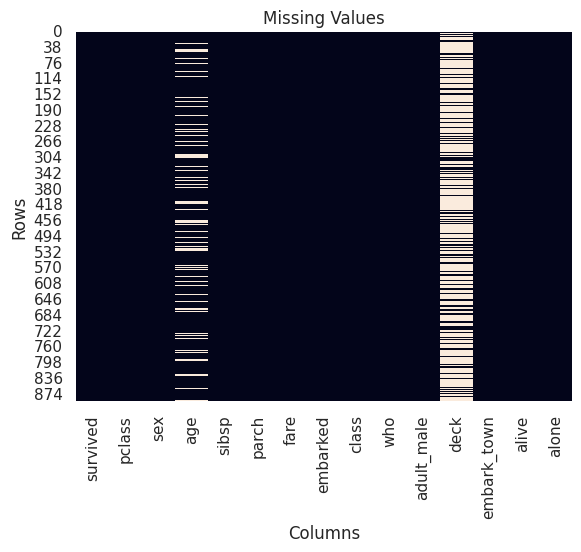

In [ ]:
# TODO: compute titanic.isnull().sum()
# TODO: also compute it as a percentage of total rows
titanic.isnull().sum()
titanic.isnull().mean()
# TODO (visualization): plot a heatmap of missing values, e.g.
# sns.heatmap(titanic.isnull(), cbar=False)
sns.heatmap(titanic.isnull(), cbar=False)
plt.xlabel('Columns')
plt.ylabel('Rows')
plt.title('Missing Values')
plt.show()

**1.4 Target Variable Distribution**

Is `survived` balanced or imbalanced? This matters for how we should judge "accuracy" later in Part 3.

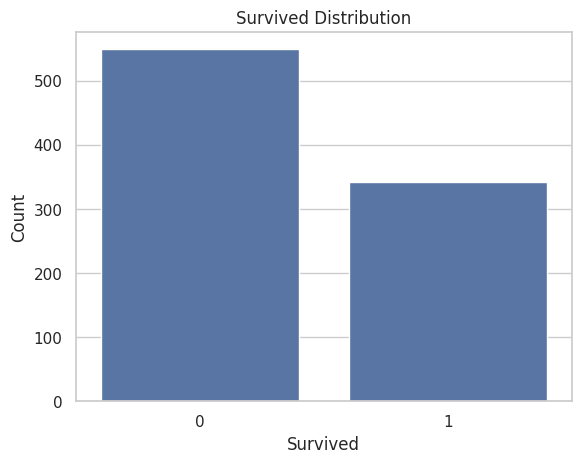

survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64


In [ ]:
# TODO: sns.countplot the 'survived' column
# TODO: print the exact percentage split (value_counts(normalize=True))
sns.countplot(x='survived', data=titanic)
plt.xlabel('Survived')
plt.ylabel('Count')
plt.title('Survived Distribution')
plt.show()
print(titanic['survived'].value_counts(normalize=True))


**1.5 Univariate Analysis**

Look at `age` and `fare` individually — shape of distribution, and whether they look skewed (relevant for Member B's transformation step later).

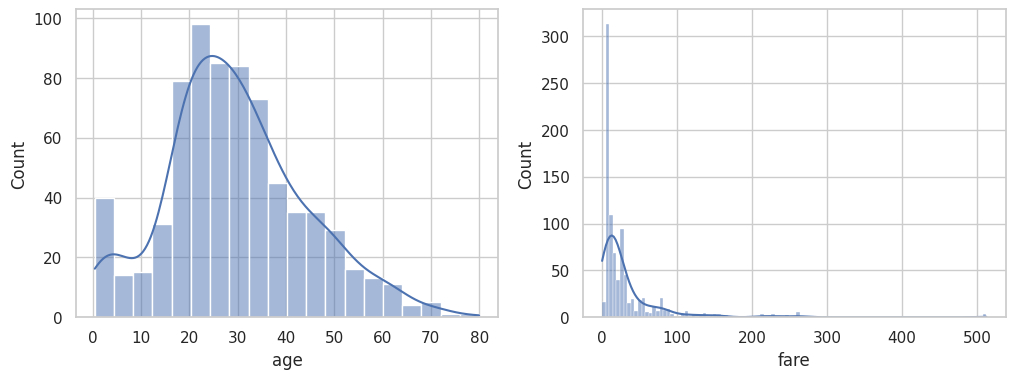

0.38910778230082704
4.787316519674893


In [ ]:
# TODO: plot a histogram (with KDE) of 'age'
# TODO: plot a histogram (with KDE) of 'fare'
# TODO: print titanic['age'].skew() and titanic['fare'].skew()
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(titanic['age'], kde=True, ax=axs[0])
sns.histplot(titanic['fare'], kde=True, ax=axs[1])
plt.show()
print(titanic['age'].skew())
print(titanic['fare'].skew())


**1.6 Bivariate Analysis — Does Survival Depend on Sex and Class?**

Compute and visualize survival rate broken down by `sex`, and separately by `pclass`.

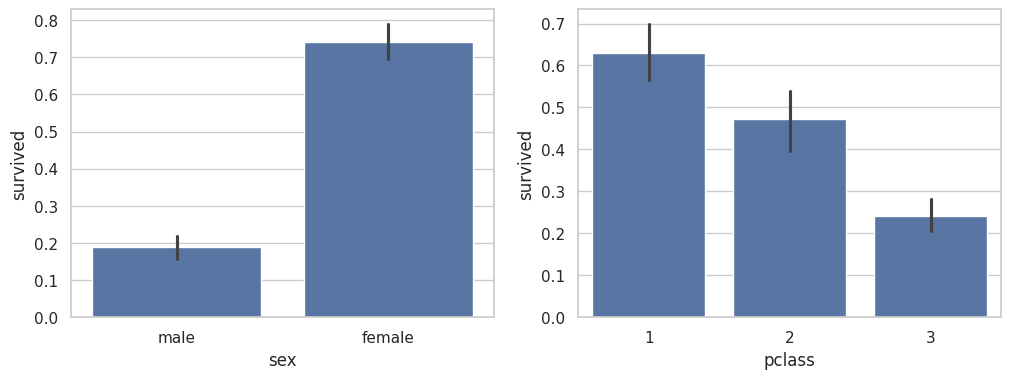

In [ ]:
# TODO: titanic.groupby('sex')['survived'].mean()
# TODO: titanic.groupby('pclass')['survived'].mean()
# TODO: visualize both with sns.barplot or sns.catplot
titanic.groupby('sex')['survived'].mean()
titanic.groupby('pclass')['survived'].mean()
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x='sex', y='survived', data=titanic, ax=axs[0])
sns.barplot(x='pclass', y='survived', data=titanic, ax=axs[1])
plt.show()


**1.7 Connecting to Bayes' Theorem**

Recall **Bayes' Theorem**:

$$P(A \mid B) = \frac{P(B \mid A)\, P(A)}{P(B)}$$

Let's estimate, **by hand**, the probability a passenger survived *given* they were female — i.e. $P(\text{Survived}=1 \mid \text{Sex}=\text{female})$ — using only priors and likelihoods computed from the data (not `groupby` directly), and then check it against the true empirical value from Section 1.6.

- $P(A) = P(\text{Survived}=1)$ → the overall survival rate
- $P(B) = P(\text{Sex}=\text{female})$ → the overall proportion of female passengers
- $P(B \mid A) = P(\text{Sex}=\text{female} \mid \text{Survived}=1)$ → among survivors, what fraction were female?

In [ ]:
# TODO: P_A = P(Survived = 1)          -> titanic['survived'].mean()
# TODO: P_B = P(Sex = female)             -> (titanic['sex'] == 'female').mean()
# TODO: P_B_given_A = P(Sex=female | Survived=1)
#       hint: filter titanic where survived == 1, then compute the fraction that are female

# TODO: apply Bayes' Theorem: P_A_given_B = (P_B_given_A * P_A) / P_B
# TODO: print P_A_given_B and compare it to titanic.groupby('sex')['survived'].mean()['female'] from Section 1.6
# They should match (up to rounding) - if not, recheck your probabilities above!


**💡 Why this matters:** Naive Bayes classifiers work by applying exactly this formula to **every feature**, multiplying the likelihoods together under the "naive" independence assumption — Member C will build on this in Part 3.

**Hand off to Member B:** the raw `titanic` DataFrame, plus your findings on which columns are missing and which numeric columns are skewed.

#### **Part 2 (Member B): Data Cleaning, Transformation & Encoding**

**Your job:** take the raw `titanic` DataFrame and Member A's findings, and produce a fully cleaned, encoded, scaled, model-ready `X_train_final` / `X_test_final`.

**2.1 Selecting Columns and Splitting Train/Test First**

We split **before** cleaning so every fitted step (imputer, encoder, scaler) is learned only from `X_train` — this avoids **data leakage** into the test set.

In [ ]:
from sklearn.model_selection import train_test_split

# Keep a focused set of columns for this lab
cols = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'survived']
df = titanic[cols].copy()

# TODO: X = df.drop(columns=['survived']), y = df['survived']
# TODO: train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
#       name the results X_train, X_test, y_train, y_test
X=df.drop(columns=['survived'])
y=df['survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train.head()


,pclass,sex,age,sibsp,parch,fare,embarked
692,3,male,NaN,0,0,56.4958,S
481,2,male,NaN,0,0,0.0000,S
527,1,male,NaN,0,0,221.7792,S
855,3,female,18.0,0,1,9.3500,S
801,2,female,31.0,1,1,26.2500,S


**2.2 Handling Missing Values**

From Part 1.3, `age` and `embarked` have missing values. Impute `age` with the **median** (robust to skew) and `embarked` with the **mode** (most frequent category) — fit on train, apply to both.

In [ ]:
from sklearn.impute import SimpleImputer

# TODO: num_imputer = SimpleImputer(strategy='median')
# TODO: fit num_imputer on X_train[['age']], then transform both X_train and X_test 'age' column
num_imputer = SimpleImputer(strategy='median')
X_train[['age']] = num_imputer.fit_transform(X_train[['age']])
X_test[['age']] = num_imputer.transform(X_test[['age']])
# TODO: cat_imputer = SimpleImputer(strategy='most_frequent')
# TODO: fit cat_imputer on X_train[['embarked']], then transform both X_train and X_test 'embarked' column
cat_imputer = SimpleImputer(strategy='most_frequent')
X_train[['embarked']] = cat_imputer.fit_transform(X_train[['embarked']])
X_test[['embarked']] = cat_imputer.transform(X_test[['embarked']])
# TODO: confirm no missing values remain with .isnull().sum()
print(X_train.isnull().sum())
print(X_test.isnull().sum())

pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64


**2.3 Binning — Creating an `age_group` Feature (Custom Binning)**

Convert continuous `age` into meaningful, ordered groups using domain knowledge — a **custom binning** approach, with edges we choose ourselves:

`Child (0–12)` < `Teen (13–19)` < `Adult (20–59)` < `Senior (60+)`

In [ ]:
age_bins = [0, 12, 19, 59, 100]
age_labels = ['Child', 'Teen', 'Adult', 'Senior']

# TODO: X_train['age_group'] = pd.cut(X_train['age'], bins=age_bins, labels=age_labels)
# TODO: do the same for X_test['age_group']
# TODO: print value_counts() of the new column to sanity-check the split
X_train['age_group'] = pd.cut(X_train['age'], bins=age_bins, labels=age_labels)
X_test['age_group'] = pd.cut(X_test['age'], bins=age_bins, labels=age_labels)
print(X_train['age_group'].value_counts())
print(X_test['age_group'].value_counts())

age_group
Adult     565
Teen       74
Child      55
Senior     18
Name: count, dtype: int64
age_group
Adult     136
Teen       21
Child      14
Senior      8
Name: count, dtype: int64


**2.4 Binning — `fare_level` Feature (Unsupervised, Quantile Binning)**

Now try an **unsupervised** binning method on `fare`: split it into 4 **equal-frequency (quantile)** bins using `KBinsDiscretizer`, fit only on the training data.

In [ ]:
from sklearn.preprocessing import KBinsDiscretizer

# TODO: kb = KBinsDiscretizer(n_bins=4, encode='ordinal', strategy='quantile')
# TODO: fit kb on X_train[['fare']]
# TODO: X_train['fare_level'] = kb.transform(X_train[['fare']])
# TODO: X_test['fare_level']  = kb.transform(X_test[['fare']])
# TODO: print kb.bin_edges_ to see the learned edges
kb = KBinsDiscretizer(n_bins=4, encode='ordinal', strategy='quantile')
kb.fit(X_train[['fare']])
X_train['fare_level'] = kb.transform(X_train[['fare']])
X_test['fare_level'] = kb.transform(X_test[['fare']])
print(kb.bin_edges_)

[array([  0.    ,   7.8958,  14.4542,  31.    , 512.3292])]


**2.5 Binarization**

Create a simple binary flag: `is_child` = 1 if `age` < 13, else 0 — using `Binarizer`.

In [ ]:
from sklearn.preprocessing import Binarizer

# TODO: binarizer = Binarizer(threshold=12.9)   # threshold is exclusive (>), so 12.9 makes 13+ map to 1... check this makes <13 -> 0
# TODO: X_train['is_child'] = binarizer.fit_transform(X_train[['age']])
# TODO: X_test['is_child']  = binarizer.transform(X_test[['age']])
binarizer = Binarizer(threshold=12.9)
X_train['is_child'] = binarizer.fit_transform(X_train[['age']])
X_test['is_child'] = binarizer.transform(X_test[['age']])

**2.6 Encoding Categorical Features**

Three different encoders for three different situations:

- **Ordinal Encoding** → `age_group` has a real order (`Child < Teen < Adult < Senior`), so use `OrdinalEncoder` with that explicit order.
- **One-Hot Encoding** → `sex` and `embarked` are nominal (no order), so use `OneHotEncoder`.
- **Label Encoding** → as a quick demo only: label-encode `titanic['alive']` (the text `yes`/`no` version of the target) separately, just to see how `LabelEncoder` works on a target-like column. (We won't use this encoded column in modeling — `survived` is already numeric.)

In [ ]:
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, LabelEncoder

# --- Ordinal Encoding for age_group ---
# TODO: oe = OrdinalEncoder(categories=[['Child', 'Teen', 'Adult', 'Senior']])
# TODO: fit oe on X_train[['age_group']], transform X_train and X_test 'age_group' column
oe = OrdinalEncoder(categories=[['Child', 'Teen', 'Adult', 'Senior']])
X_train[['age_group']] = oe.fit_transform(X_train[['age_group']])
X_test[['age_group']] = oe.transform(X_test[['age_group']])
print(oe.categories_)
# --- One-Hot Encoding for sex, embarked (we'll actually apply this via ColumnTransformer in 2.7) ---
# (no code needed here yet - just review the OneHotEncoder import above)

# --- Label Encoding demo on titanic['alive'] ---
# TODO: le = LabelEncoder()
# TODO: alive_encoded = le.fit_transform(titanic['alive'])
# TODO: print le.classes_ and the first 10 values of alive_encoded
le = LabelEncoder()
alive_encoded = le.fit_transform(titanic['alive'])
print(le.classes_)
print(alive_encoded[:10])

[array(['Child', 'Teen', 'Adult', 'Senior'], dtype=object)]
['no' 'yes']
[0 1 1 1 0 0 0 0 1 1]


**2.7 Combining Everything with `ColumnTransformer`**

Instead of manually encoding and concatenating column-by-column, bundle the remaining raw categorical columns (`sex`, `embarked`) into one `ColumnTransformer`, and pass the already-processed numeric/ordinal columns straight through.

In [ ]:
from sklearn.compose import ColumnTransformer

# TODO: define a ColumnTransformer with:
#   ('ohe', OneHotEncoder(drop='first'), ['sex', 'embarked'])
# and remainder='passthrough' to keep age, age_group_encoded, fare, fare_level, is_child, pclass, sibsp, parch
columntransformer = ColumnTransformer(
    [('ohe', OneHotEncoder(drop='first'), ['sex', 'embarked'])],
    remainder='passthrough'
)
# TODO: fit_transform on X_train (careful: only fit on train!), transform on X_test
# TODO: print the resulting shapes of X_train and X_test after this step
X_train_final = columntransformer.fit_transform(X_train)
X_test_final = columntransformer.transform(X_test)
print(X_train_final.shape)
print(X_test_final.shape)

(712, 11)
(179, 11)


**2.8 Reducing Skew — Power Transformer**

From Part 1.5, `fare` is heavily right-skewed. Apply a `PowerTransformer` (Yeo-Johnson, since `fare` can be 0) to `fare` before scaling.

In [ ]:
from sklearn.preprocessing import PowerTransformer

# TODO: pt = PowerTransformer(method='yeo-johnson')
# TODO: fit pt on the training 'fare' column, transform both train and test 'fare' columns
# TODO: compare skewness of 'fare' before vs after using pandas .skew()
pt = PowerTransformer(method='yeo-johnson')
pt.fit(X_train[['fare']])
X_train[['fare']] = pt.transform(X_train[['fare']])
X_test[['fare']] = pt.transform(X_test[['fare']])

print(X_train['fare'].skew())
print(X_test['fare'].skew())

-0.030504795464933083
0.5661317664077957


**2.9 Feature Scaling — Standardization vs Normalization**

Two common scaling techniques:

- **Standardization (Z-score):** $x' = \dfrac{x - \mu}{\sigma}$ → mean 0, std 1. Use `StandardScaler`.
- **Normalization (Min-Max):** $x' = \dfrac{x - \min(x)}{\max(x) - \min(x)}$ → scales to a fixed $[0,1]$ range. Use `MinMaxScaler`.

Pick **one** to apply to the final numeric columns (e.g., `age`, `fare`) — fit on train, transform both.

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# TODO: choose StandardScaler() OR MinMaxScaler()
# TODO: fit on the numeric columns of X_train, transform both X_train and X_test
# TODO: name your final, fully-processed feature sets X_train_final and X_test_final
sc = StandardScaler()
X_train_final[:, -8:] = sc.fit_transform(X_train_final[:, -8:])
X_test_final[:, -8:] = sc.transform(X_test_final[:, -8:])

**Hand off to Member C:** `X_train_final`, `X_test_final`, `y_train`, `y_test` — the model-ready data.

#### **Part 3 (Member C): Naive Bayes Modeling, Cross-Validation & Evaluation**

**Your job:** train Naive Bayes two ways (from scratch and with `sklearn`), validate it properly, and compare results — including whether Member B's preprocessing actually helped.

**3.1 Bayes' Theorem Recap → the Naive Bayes Formula**

Member A estimated $P(\text{Survived} \mid \text{Sex})$ for **one** feature by hand in Section 1.7. Naive Bayes generalizes this to **all** features at once, assuming they're conditionally independent given the class:

$$P(y \mid x_1, ..., x_n) \propto P(y) \prod_{i=1}^{n} P(x_i \mid y)$$

- $P(y)$ → the **prior** (class probability, e.g. overall survival rate)
- $P(x_i \mid y)$ → the **likelihood** of feature $i$ given the class (for continuous features, modeled with a Gaussian):

$$P(x_i \mid y) = \frac{1}{\sqrt{2\pi\sigma_y^2}} \exp\left(-\frac{(x_i - \mu_y)^2}{2\sigma_y^2}\right)$$

- The predicted class is whichever $y$ **maximizes** this product (in practice, the **sum of log-probabilities**, to avoid numerical underflow).

**3.2 Implementing Gaussian Naive Bayes From Scratch**

Follow the 3-step process below.

In [ ]:
class GaussianNaiveBayesScratch:
    def fit(self, X, y):
        self.classes = np.unique(y)
        self.priors = {}
        self.mean = {}
        self.var = {}
        for c in self.classes:
            X_c = X[y == c]
            # TODO: self.priors[c] = P(y = c)  -> fraction of training rows with this class
            # TODO: self.mean[c] = mean of each feature in X_c (X_c.mean(axis=0))
            # TODO: self.var[c]  = variance of each feature in X_c (X_c.var(axis=0))
            pass

    def _gaussian_pdf(self, x, mean, var):
        # TODO: implement the Gaussian formula above, elementwise, using numpy
        pass

    def predict(self, X):
        preds = []
        for x in X:
            posteriors = {}
            for c in self.classes:
                # TODO: log_prior = np.log(self.priors[c])
                # TODO: log_likelihood = sum(np.log(self._gaussian_pdf(x, self.mean[c], self.var[c])))
                # TODO: posteriors[c] = log_prior + log_likelihood
                pass
            # TODO: preds.append(the class with the highest posterior)
        return np.array(preds)

# TODO: instantiate the class, call .fit(X_train_final, y_train.values)
# TODO: predict on X_test_final, store as y_pred_scratch


**3.3 Naive Bayes Using `scikit-learn` (`GaussianNB`)**

`sklearn` provides several Naive Bayes variants depending on feature type — we use `GaussianNB` since our features are continuous after Part 2's scaling:
- `GaussianNB` → continuous features (our case)
- `MultinomialNB` → discrete counts (e.g., word frequencies in text)
- `BernoulliNB` → binary/boolean features
- `CategoricalNB` → raw categorical features (discrete, unencoded)

In [ ]:
from sklearn.naive_bayes import GaussianNB

# TODO: model = GaussianNB()
# TODO: model.fit(X_train_final, y_train)
# TODO: y_pred_sklearn = model.predict(X_test_final)
model = GaussianNB()
model.fit(X_train_final, y_train)
y_pred_sklearn = model.predict(X_test_final)

**3.4 Cross-Validation for a More Reliable Estimate**

A single train/test split can be lucky or unlucky. `cross_val_score` repeats training/evaluation across multiple folds and averages the results:

$$\text{CV Score} = \frac{1}{k}\sum_{i=1}^{k} \text{Accuracy}_i$$

In [ ]:
from sklearn.model_selection import cross_val_score

# TODO: use cross_val_score(GaussianNB(), X_train_final, y_train, cv=5)
# TODO: print the individual fold scores, plus the mean and standard deviation
cv = cross_val_score(GaussianNB(), X_train_final, y_train, cv=5)
print(cv)
print(cv.mean())
print(cv.std())

[0.72727273 0.74825175 0.78873239 0.83802817 0.78873239]
0.7782034866541908
0.038188368122188614


**3.5 Model Evaluation — Accuracy & Confusion Matrix**

- **Accuracy:** $\dfrac{TP + TN}{TP + TN + FP + FN}$ — overall correctness (less informative if classes are imbalanced, per Part 1.4).
- **Confusion Matrix:** shows exactly which classes get confused with which.

0.770949720670391


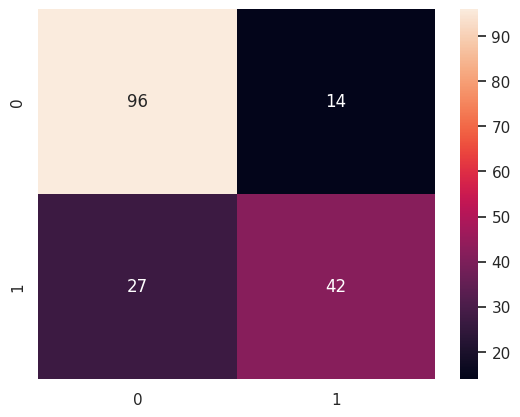

              precision    recall  f1-score   support

           0       0.78      0.87      0.82       110
           1       0.75      0.61      0.67        69

    accuracy                           0.77       179
   macro avg       0.77      0.74      0.75       179
weighted avg       0.77      0.77      0.77       179



In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# TODO: print accuracy_score for both y_pred_scratch and y_pred_sklearn
# TODO: compute confusion_matrix for y_pred_sklearn and plot it with sns.heatmap(annot=True)
# TODO: print classification_report for y_pred_sklearn
accuracy = accuracy_score(y_test, y_pred_sklearn)
#accuracy_scratch = accuracy_score(y_test, y_pred_scratch)

print(accuracy)
#print(accuracy_scratch)
cm = confusion_matrix(y_test, y_pred_sklearn)
sns.heatmap(cm, annot=True)
plt.show()
print(classification_report(y_test, y_pred_sklearn))

**3.6 Final Comparison: Does All That Preprocessing Actually Help?**

Train one more `GaussianNB` on a **minimally processed** baseline (just impute missing `age`, drop other categorical columns) and compare its cross-validated accuracy to Member B's fully processed pipeline from Section 3.4.

In [ ]:
# TODO: build a quick baseline: X_baseline = titanic[['pclass','age','sibsp','parch','fare']] (imputed age only, no encoding/scaling/binning)
# TODO: run the same cross_val_score(GaussianNB(), X_baseline, y, cv=5) on it
# TODO: print both mean CV accuracies side-by-side and comment on the difference

X_baseline = titanic[['pclass','age','sibsp','parch','fare']]
X_baseline[['age']] = num_imputer.fit_transform(X_baseline[['age']])
cv_baseline = cross_val_score(GaussianNB(), X_baseline, y, cv=5)
print(cv_baseline.mean())
print(cv.mean())


0.6768438892724876
0.7782034866541908


**Compare your 3 results:** from-scratch NB, `sklearn` NB on the full pipeline, and `sklearn` NB on the raw baseline. They should mostly agree in *direction* even if the exact numbers differ slightly.

#### **Wrap-Up: Group Reflection (Answer Together)**

As a group, discuss and write your answers in the cell below:

1. Which single preprocessing step from Part 2 do you think improved accuracy the most, and why?
2. How closely did your hand-computed Bayes' Theorem probability (Section 1.7) match the true empirical survival rate for women? If they didn't match exactly, why not?
3. Which Naive Bayes variant (`Gaussian`/`Multinomial`/`Bernoulli`/`Categorical`) would you choose for a spam-detection problem based on word counts, and why?
4. Why did we split the data into train/test **before** imputing, encoding, and scaling in Part 2, instead of doing it on the whole dataset first?

*Group answers here:*

1.
2.
3.
4.